In [1]:
import pandas as pd
df = pd.read_csv("../data/clean/merged_data_sets.csv")

C:\Users\chukk\AppData\Local\Temp\ipykernel_30072\546622613.py:2: DtypeWarning: Columns (2: Variation) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/clean/merged_data_sets.csv")


In [2]:
df

,Unnamed: 0,client_id,Variation,visitor_id,visit_id,process_step,date_time,client_tenure_yr,client_tenure_mnth,client_age,gender,num_accts,total_balance,calls_6_mnth,logons_6_mnth
0,0,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
1,1,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
2,2,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
3,3,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
4,4,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449826,449826,9895983,NaN,473024645_56027518531,498981662_93503779869_272484,step_3,2017-06-15 19:52:09,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0
449827,449827,9895983,NaN,473024645_56027518531,498981662_93503779869_272484,step_2,2017-06-15 19:50:37,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0
449828,449828,9895983,NaN,473024645_56027518531,498981662_93503779869_272484,step_1,2017-06-15 19:50:05,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0
449829,449829,9895983,NaN,473024645_56027518531,498981662_93503779869_272484,start,2017-06-15 19:50:00,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0


In [3]:
df = df.drop(columns=["Unnamed: 0"])

In [4]:
df

,client_id,Variation,visitor_id,visit_id,process_step,date_time,client_tenure_yr,client_tenure_mnth,client_age,gender,num_accts,total_balance,calls_6_mnth,logons_6_mnth
0,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
1,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
2,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
3,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
4,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04,5.0,64.0,79.0,Unspecified,2.0,189023.86,1.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449826,9895983,NaN,473024645_56027518531,498981662_93503779869_272484,step_3,2017-06-15 19:52:09,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0
449827,9895983,NaN,473024645_56027518531,498981662_93503779869_272484,step_2,2017-06-15 19:50:37,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0
449828,9895983,NaN,473024645_56027518531,498981662_93503779869_272484,step_1,2017-06-15 19:50:05,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0
449829,9895983,NaN,473024645_56027518531,498981662_93503779869_272484,start,2017-06-15 19:50:00,10.0,121.0,49.0,Male,2.0,97748.22,2.0,2.0


In [5]:
df.duplicated().sum()

np.int64(5934)

In [6]:
df = df.drop_duplicates()

In [7]:
df.duplicated().sum()

np.int64(0)

## Charles Hypothesis Testing

In [8]:
df = df[df["Variation"].isin(["Test", "Control"])].copy()
df["date_time"] = pd.to_datetime(df["date_time"])

In [9]:
df_independent = df[["Variation", "client_id", "visit_id", "process_step", "date_time"]].copy()
display(df_independent)
display(df_independent.dtypes)

,Variation,client_id,visit_id,process_step,date_time
0,Test,9988021,781255054_21935453173_531117,step_3,2017-04-17 15:27:07
1,Test,9988021,781255054_21935453173_531117,step_2,2017-04-17 15:26:51
2,Test,9988021,781255054_21935453173_531117,step_3,2017-04-17 15:19:22
3,Test,9988021,781255054_21935453173_531117,step_2,2017-04-17 15:19:13
4,Test,9988021,781255054_21935453173_531117,step_3,2017-04-17 15:18:04
...,...,...,...,...,...
321304,Test,6334360,586047816_14599436811_389185,step_2,2017-04-11 08:45:38
321305,Test,6334360,586047816_14599436811_389185,step_1,2017-04-11 08:44:43
321306,Test,6334360,586047816_14599436811_389185,step_2,2017-04-11 08:44:30
321307,Test,6334360,586047816_14599436811_389185,step_1,2017-04-11 08:42:36


Variation                  str
client_id                int64
visit_id                   str
process_step               str
date_time       datetime64[us]
dtype: object

In [10]:
steps = ["start", "step_1", "step_2", "step_3", "confirm"]

# One row per client, number of times each step was recorded
client_crosstab = (
    pd.crosstab([df_independent["client_id"], df_independent["Variation"]], df_independent["process_step"])
      .reset_index()
      .rename_axis(columns=None)
)

client_crosstab["completed"] = (client_crosstab[steps] >= 1).all(axis=1)
display(client_crosstab)

,client_id,Variation,confirm,start,step_1,step_2,step_3,completed
0,555,Test,1,1,1,1,1,True
1,647,Test,1,1,1,1,1,True
2,934,Test,0,4,0,0,0,False
3,1028,Control,0,1,5,2,1,False
4,1104,Control,0,2,0,0,0,False
...,...,...,...,...,...,...,...,...
50495,9999150,Test,0,2,1,0,0,False
50496,9999400,Test,1,1,1,1,1,True
50497,9999626,Test,0,1,1,0,0,False
50498,9999729,Test,1,4,3,2,1,True


Checking statistics of the groups vs Catarina & Francesco data

In [11]:
print('-'*10 + 'Clients who completed the process' + '-'*10)
print(client_crosstab["completed"].sum()) 
print('\n' + '-'*10 + 'Variation split of completed clients' + '-'*10)
print(client_crosstab.groupby("Variation")["completed"].sum())
print('\n' + '-'*10 + 'Table of clients completions vs incompletions final table' + '-'*10)
display(client_crosstab)

----------Clients who completed the process----------
33544

----------Variation split of completed clients----------
Variation
Control    15206
Test       18338
Name: completed, dtype: int64

----------Table of clients completions vs incompletions final table----------


,client_id,Variation,confirm,start,step_1,step_2,step_3,completed
0,555,Test,1,1,1,1,1,True
1,647,Test,1,1,1,1,1,True
2,934,Test,0,4,0,0,0,False
3,1028,Control,0,1,5,2,1,False
4,1104,Control,0,2,0,0,0,False
...,...,...,...,...,...,...,...,...
50495,9999150,Test,0,2,1,0,0,False
50496,9999400,Test,1,1,1,1,1,True
50497,9999626,Test,0,1,1,0,0,False
50498,9999729,Test,1,4,3,2,1,True


In [12]:
df_finished_clients = client_crosstab[client_crosstab["completed"] == True]

In [13]:
finished_clients_lst = df_finished_clients["client_id"]
type(finished_clients_lst)

pandas.Series

In [14]:
df_hypo_test = df_independent[df_independent["client_id"].isin(finished_clients_lst)].copy()

In [15]:
df_hypo_test = df_hypo_test.sort_values(["client_id", "date_time"])

In [16]:
df_hypo_test["step_time"] = df_hypo_test.groupby("client_id")["date_time"].diff()
display(df_hypo_test)

,Variation,client_id,visit_id,process_step,date_time,step_time
94261,Test,555,637149525_38041617439_716659,start,2017-04-15 12:57:56,NaT
94260,Test,555,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,0 days 00:00:07
94259,Test,555,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,0 days 00:00:32
94258,Test,555,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,0 days 00:01:39
94257,Test,555,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,0 days 00:00:20
...,...,...,...,...,...,...
140284,Test,9999729,870243567_56915814033_814203,start,2017-05-08 16:08:25,18 days 01:39:28
140283,Test,9999729,870243567_56915814033_814203,step_1,2017-05-08 16:08:30,0 days 00:00:05
140282,Test,9999729,870243567_56915814033_814203,step_2,2017-05-08 16:08:40,0 days 00:00:10
140281,Test,9999729,870243567_56915814033_814203,step_3,2017-05-08 16:09:19,0 days 00:00:39


In [17]:
idle_steps = df_hypo_test[df_hypo_test["step_time"] > pd.Timedelta(minutes=30)]

In [18]:
df_hypo_test["active_time"] = df_hypo_test["step_time"]
display(df_hypo_test)

,Variation,client_id,visit_id,process_step,date_time,step_time,active_time
94261,Test,555,637149525_38041617439_716659,start,2017-04-15 12:57:56,NaT,NaT
94260,Test,555,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,0 days 00:00:07,0 days 00:00:07
94259,Test,555,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,0 days 00:00:32,0 days 00:00:32
94258,Test,555,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,0 days 00:01:39,0 days 00:01:39
94257,Test,555,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,0 days 00:00:20,0 days 00:00:20
...,...,...,...,...,...,...,...
140284,Test,9999729,870243567_56915814033_814203,start,2017-05-08 16:08:25,18 days 01:39:28,18 days 01:39:28
140283,Test,9999729,870243567_56915814033_814203,step_1,2017-05-08 16:08:30,0 days 00:00:05,0 days 00:00:05
140282,Test,9999729,870243567_56915814033_814203,step_2,2017-05-08 16:08:40,0 days 00:00:10,0 days 00:00:10
140281,Test,9999729,870243567_56915814033_814203,step_3,2017-05-08 16:09:19,0 days 00:00:39,0 days 00:00:39


In [19]:
idle_rows = df_hypo_test["step_time"] > pd.Timedelta(minutes=30)
display(idle_rows)

94261     False
94260     False
94259     False
94258     False
94257     False
          ...  
140284     True
140283    False
140282    False
140281    False
140280    False
Name: step_time, Length: 240978, dtype: bool

In [20]:
df_hypo_test.loc[idle_rows, "active_time"] = pd.Timedelta(0)

In [21]:
print((df_hypo_test["active_time"] > pd.Timedelta(minutes=30)).sum())
print((df_hypo_test["step_time"] > pd.Timedelta(minutes=30)).sum())

0
12401


In [22]:
display(df_hypo_test)

,Variation,client_id,visit_id,process_step,date_time,step_time,active_time
94261,Test,555,637149525_38041617439_716659,start,2017-04-15 12:57:56,NaT,NaT
94260,Test,555,637149525_38041617439_716659,step_1,2017-04-15 12:58:03,0 days 00:00:07,0 days 00:00:07
94259,Test,555,637149525_38041617439_716659,step_2,2017-04-15 12:58:35,0 days 00:00:32,0 days 00:00:32
94258,Test,555,637149525_38041617439_716659,step_3,2017-04-15 13:00:14,0 days 00:01:39,0 days 00:01:39
94257,Test,555,637149525_38041617439_716659,confirm,2017-04-15 13:00:34,0 days 00:00:20,0 days 00:00:20
...,...,...,...,...,...,...,...
140284,Test,9999729,870243567_56915814033_814203,start,2017-05-08 16:08:25,18 days 01:39:28,0 days 00:00:00
140283,Test,9999729,870243567_56915814033_814203,step_1,2017-05-08 16:08:30,0 days 00:00:05,0 days 00:00:05
140282,Test,9999729,870243567_56915814033_814203,step_2,2017-05-08 16:08:40,0 days 00:00:10,0 days 00:00:10
140281,Test,9999729,870243567_56915814033_814203,step_3,2017-05-08 16:09:19,0 days 00:00:39,0 days 00:00:39


In [23]:
df_effective = df_hypo_test.groupby(['client_id', 'Variation'])["active_time"].sum().dt.total_seconds().reset_index()
display(df_effective)

,client_id,Variation,active_time
0,555,Test,158.0
1,647,Test,377.0
2,1195,Control,245.0
3,1197,Control,95.0
4,1336,Test,293.0
...,...,...,...
33539,9998851,Test,165.0
33540,9998964,Test,252.0
33541,9999009,Test,171.0
33542,9999400,Test,119.0


In [24]:
display(df_effective.groupby("Variation")["active_time"].agg(["count", "mean", "median"]))
print("Clients with 0 seconds:", (df_effective["active_time"] == 0).sum())

,count,mean,median
Variation,,,
Control,15206,456.419966,298.0
Test,18338,471.203675,280.0


Clients with 0 seconds: 0


Table is reproducing effective times of Francesco's segments

In [25]:
import scipy.stats as st
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np

%matplotlib inline

df_test = df_effective[df_effective["Variation"] == "Test"]
df_control = df_effective[df_effective["Variation"] == "Control"]

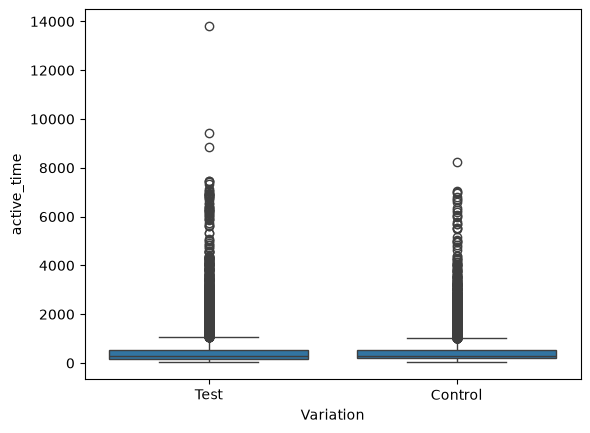

In [26]:
sns.boxplot(data=df_effective, x="Variation", y="active_time")
plt.show()

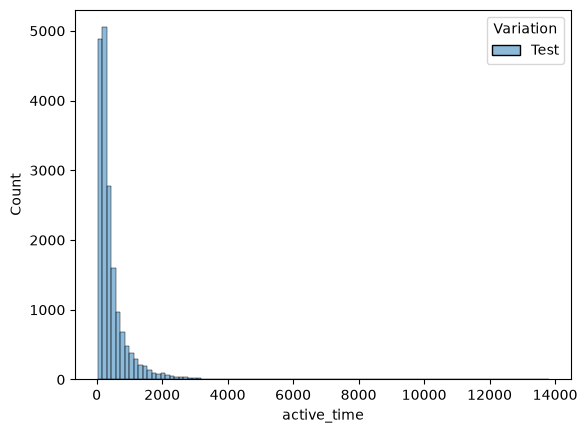

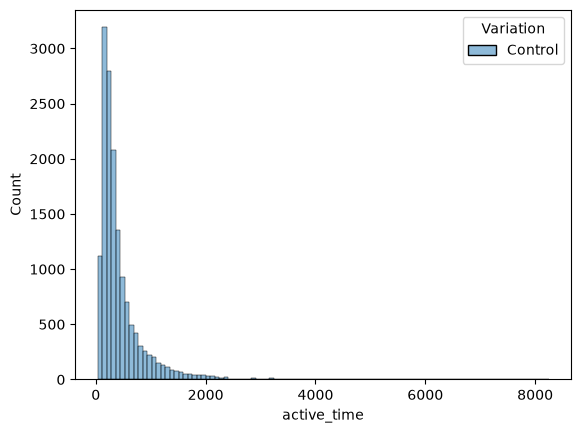

In [27]:
df_control = df_effective[df_effective["Variation"] == "Control"]
sns.histplot(data=df_test, x="active_time", hue="Variation", bins=100)
plt.show()

df_test = df_effective[df_effective["Variation"] == "Test"]
sns.histplot(data=df_control, x="active_time", hue="Variation", bins=100)
plt.show()

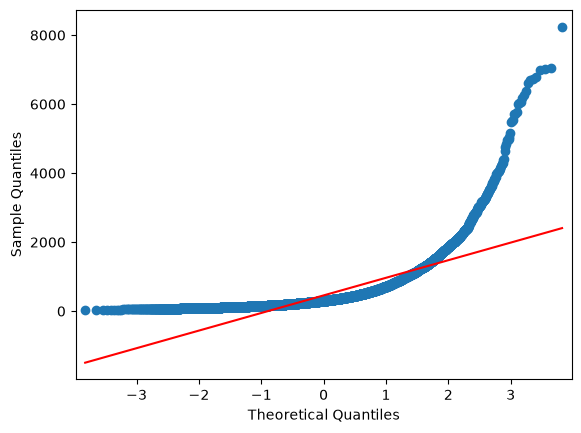

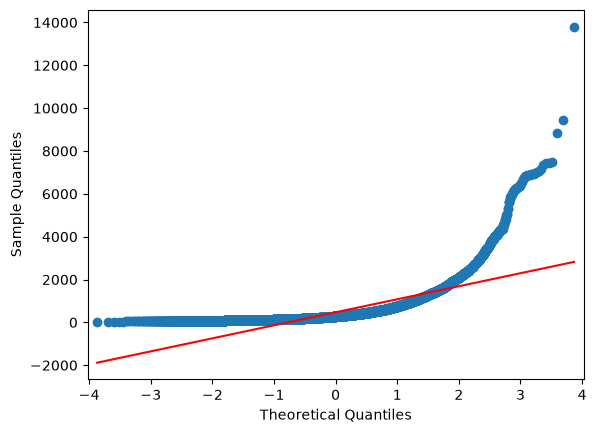

In [28]:
sm.qqplot(df_control['active_time'], line='s');
sm.qqplot(df_test['active_time'], line='s');

In [29]:
# Conducting the Kolmogorov-Smirnov test for normality on 'Step Time'
# First, we need to standardize the data to have mean 0 and variance 1 since we're comparing against a standard normal distribution
standardized_step_time = (df_control['active_time'] - df_control['active_time'].mean()) / df_control['active_time'].std()
ks_test_statistic, ks_p_value = st.kstest(standardized_step_time, 'norm')

print(ks_test_statistic, ks_p_value)

0.21782948642918512 0.0


In [30]:
# print the test result
if ks_p_value < 0.05:
    print('The test results indicate that the active time spent each step is significantly different from a normal distribution.')
else:
    print('The test results indicate that the active time spent each step is not significantly different from a normal distribution.')

The test results indicate that the active time spent each step is significantly different from a normal distribution.


In [31]:
# Applying log transformation to 'SalePrice' and standardizing it
df_effective["log_time"] = np.log1p(df_effective["active_time"])

df_control = df_effective[df_effective["Variation"] == "Control"]
df_test = df_effective[df_effective["Variation"] == "Test"]

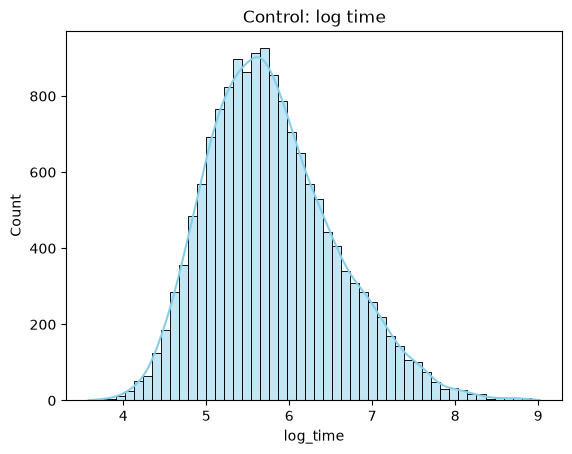

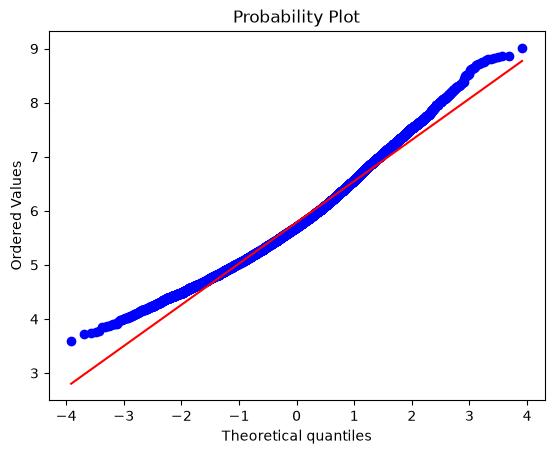

In [32]:
sns.histplot(df_control["log_time"], kde=True, bins=50, color="skyblue")
plt.title("Control: log time")
plt.show()
st.probplot(df_control["log_time"], plot=plt)
plt.show()

sns.histplot(df_test["log_time"], kde=True, bins=50, color="orange")
plt.title("Test: log time")
plt.show()
stats.probplot(df_test["log_time"], plot=plt)
plt.show()

In [33]:
log_transformed_step_time = np.log1p(df_effective["active_time"])
standardized_step_time_log = (log_transformed_step_time - log_transformed_step_time.mean()) / log_transformed_step_time.std()

In [34]:
#Rechecking our KS test
standardized_log_control = (df_control["log_time"] - df_control["log_time"].mean()) / df_control["log_time"].std()
ks_test_statistic, ks_p_value = st.kstest(standardized_log_control, 'norm')
print(ks_test_statistic, ks_p_value)

0.046855346305001544 1.8926960331586754e-29


In [35]:
# print the test result
if ks_p_value < 0.05:
    print('The test results indicate that the active time spent each step is significantly different from a normal distribution.')
else:
    print('The test results indicate that the active time spent each step is not significantly different from a normal distribution.')

The test results indicate that the active time spent each step is significantly different from a normal distribution.


## Now we hypothesis test!

In [36]:
#H0: mu_log_time Test = mu_log_time Control
#H1: mu_log_time Test != mu log_time Control

#H0: mu_log_time Test- mu_log_time Control = 0 = delta
#H1: mu_log_time Test - mu_log_time Contro != 0 = delta
alpha = 0.05


In [42]:
control_mean = df_control["log_time"].mean()
test_mean = df_test["log_time"].mean()

control_std = df_control["log_time"].std(ddof=1)
test_std = df_test["log_time"].std(ddof=1)

n1 = len(df_control["log_time"])
n2 = len(df_test["log_time"])

dof = n1 + n2 - 2

statistic = (control_mean - test_mean) / np.sqrt( (control_std**2/n1) + (test_std**2/n2))
statistic

np.float64(5.133438229527558)

In [38]:
def show_statistical_test(statistic: float, alpha: float, n: int, distribution: str=["t-student","normal"], alternative: str=["two-sided","lower","greater"]):

    if distribution not in ["t-student","normal"]:
        raise TypeError("Sorry, only 't-student', and 'normal' distributions are acepted")

    if alternative not in ["two-sided","lower","greater"]:
        raise TypeError("Sorry, only 'two-sided', 'lower', and 'greated' are acepted valued for the alternative")

    if not isinstance(statistic, float):
        raise TypeError("Sorry, the data type for the statistic must be float")

    if not isinstance(alpha, float):
        raise TypeError("Sorry, the data type for alpha must be float")

    if not isinstance(n, int):
        raise TypeError("Sorry, the data type for n must be int")

    x_values = np.linspace(-3, 3)

    if distribution == "t-student":

        y_values = st.t.pdf(x_values, df=n-1)

        if alternative == "two-sided": # Computing the critical values

            lower_critical_value = st.t.ppf(alpha/2, df=n-1)
            upper_critical_value = st.t.ppf(1-(alpha/2), df=n-1)

            x_values1 = np.linspace(-3, lower_critical_value)
            y_values1 = st.t.pdf(x_values1, df=n-1)

            x_values2 = np.linspace(upper_critical_value, 3)
            y_values2 = st.t.pdf(x_values2, df=n-1)

        elif alternative == "lower":

            critical_value = st.t.ppf(alpha, df=n-1)

            x_values1 = np.linspace(-3, critical_value)
            y_values1 = st.t.pdf(x_values1, df=n-1)

        elif alternative == "greater":

            critical_value = st.t.ppf(1-alpha, df=n-1)

            x_values2 = np.linspace(critical_value, 3)
            y_values2 = st.t.pdf(x_values2, df=n-1)

    elif distribution == "normal":

        y_values = st.norm.pdf(x_values)

        if alternative == "two-sided": # Computing the critical values

            lower_critical_value = st.norm.ppf(alpha/2)
            upper_critical_value = st.norm.ppf(1-(alpha/2))

            x_values1 = np.linspace(-3, lower_critical_value)
            y_values1 = st.norm.pdf(x_values1)

            x_values2 = np.linspace(upper_critical_value, 3)
            y_values2 = st.norm.pdf(x_values2)

        elif alternative == "lower":

            critical_value = st.norm.ppf(alpha)

            x_values1 = np.linspace(-3, critical_value)
            y_values1 = st.norm.pdf(x_values1)

        elif alternative == "greater":

            critical_value = st.norm.ppf(1-alpha)

            x_values2 = np.linspace(critical_value, 3)
            y_values2 = st.norm.pdf(x_values2)

    df = pd.DataFrame({"x": x_values, "pdf": y_values})

    title = f"{distribution} Probability Density Function"

    fig = px.line(df, x="x", y="pdf", title=title)

    if alternative == "two-sided":

        fig.add_vline(x=lower_critical_value, line_color="red")
        fig.add_vline(x=upper_critical_value, line_color="red")

        fig.add_annotation(x=lower_critical_value,y=0,text=f"Lower critical value {lower_critical_value: .2f}",xref="x",yref="paper",yanchor="bottom")
        fig.add_annotation(x=upper_critical_value,y=0,text=f"Upper critical value {upper_critical_value: .2f}",xref="x",yref="paper",yanchor="bottom")

        fig.add_scatter(x=x_values1, y=y_values1,fill='tozeroy', mode='none' , fillcolor='red')
        fig.add_scatter(x=x_values2, y=y_values2,fill='tozeroy', mode='none' , fillcolor='red')

    elif alternative == "lower":

        fig.add_vline(x=critical_value, line_color="red")
        fig.add_annotation(x=critical_value,y=0,text=f"Critical value {critical_value: .2f}",xref="x",yref="paper",yanchor="bottom")

        fig.add_scatter(x=x_values1, y=y_values1,fill='tozeroy', mode='none' , fillcolor='red')

    elif alternative == "greater":

        fig.add_vline(x=critical_value, line_color="red")
        fig.add_annotation(x=critical_value,y=0,text=f"Critical value {critical_value: .2f}",xref="x",yref="paper",yanchor="bottom")

        fig.add_scatter(x=x_values2, y=y_values2,fill='tozeroy', mode='none' , fillcolor='red')

    fig.add_vline(x=statistic)
    fig.add_annotation(x=statistic,y=0,text=f"Statistic {statistic: .2f}",xref="x",yref="paper",yanchor="bottom")

    fig.update_layout(title_text=f'{distribution} Probability Density Function', title_x=0.5)

    fig.update_layout(showlegend=False)

    fig.show()

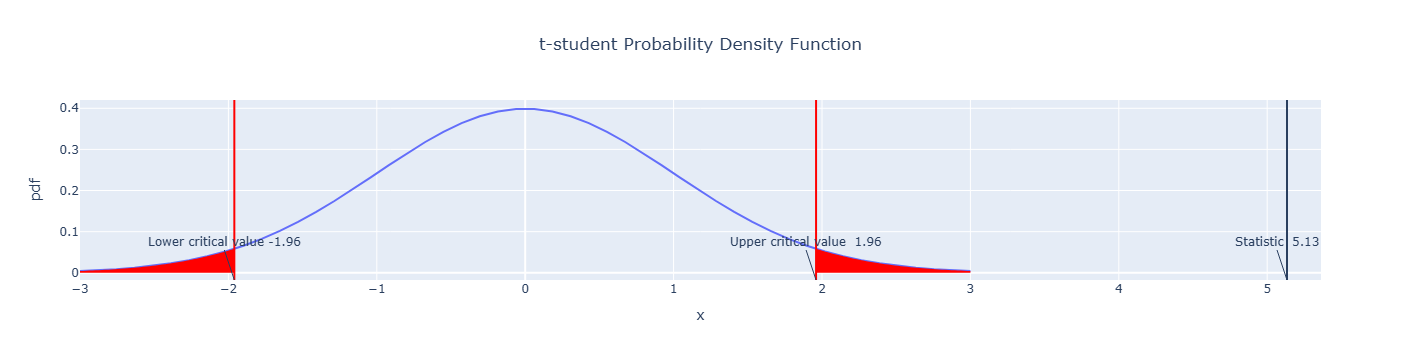

In [39]:
show_statistical_test(statistic, 0.05, n1+n2-2, distribution="t-student", alternative="two-sided")

In [44]:
print(st.t.ppf(1-(alpha/2), dof), st.norm.ppf(1-(alpha/2)))

1.960034712444793 1.959963984540054


In [45]:
st.t.cdf(statistic, dof) > 1-(0.05/2)

np.True_

In [48]:
p_value = st.t.sf(abs(statistic), dof) * 2
print(p_value)

2.86082678117878e-07


In [49]:
if p_value > alpha:
    print("We are not able to reject the null hypothesis")
else:
    print("We reject the null hypotesis")

We reject the null hypotesis
